# Week 6 Lab: MNIST Dataset

Base model: Flatten -> Dense(128, ReLU) -> Dense(10, Softmax), trained with a 20% validation split and the default batch size.

In [1]:
from pathlib import Path
import struct
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import roc_curve, auc, accuracy_score, classification_report

keras.utils.set_random_seed(42)

/Users/mac/Downloads/Masters Courses/Machine Learning/Machine_Learning_Exercises/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## Load the data

In [2]:
data_dir = Path("archive")

def load_idx_file(path):
    with open(path, "rb") as f:
        zero, data_type, dims = struct.unpack(">HBB", f.read(4))
        shape = tuple(struct.unpack(">I", f.read(4))[0] for _ in range(dims))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(shape)

X_train = load_idx_file(data_dir / "train-images.idx3-ubyte")
y_train = load_idx_file(data_dir / "train-labels.idx1-ubyte")
X_test = load_idx_file(data_dir / "t10k-images.idx3-ubyte")
y_test = load_idx_file(data_dir / "t10k-labels.idx1-ubyte")

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)


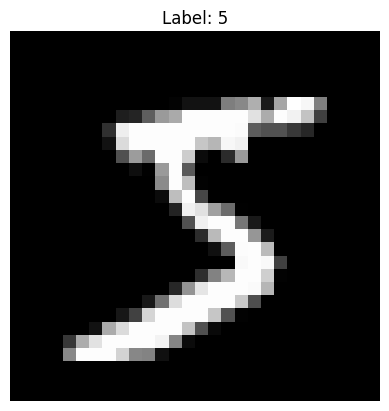

In [3]:
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

In [4]:
# scale pixels to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

# one-hot labels are only needed for the ROC curves
y_test_onehot = keras.utils.to_categorical(y_test, 10)

# validation_split=0.2 holds out the last 20%, so the model trains on the first 48000
X_fit, y_fit = X_train[:48000], y_train[:48000]

## Helper functions

In [5]:
def build_model(optimizer, l2=None, dropout=None):
    model = keras.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(layers.Flatten())
    if l2:
        model.add(layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(l2)))
    else:
        model.add(layers.Dense(128, activation="relu"))
    if dropout:
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def plot_history(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"], label="train")
    plt.plot(history.history["val_loss"], label="validation")
    plt.title(title + " - loss")
    plt.xlabel("epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["accuracy"], label="train")
    plt.plot(history.history["val_accuracy"], label="validation")
    plt.title(title + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()

    plt.show()


def plot_roc(model, title):
    # one ROC curve per digit (one-vs-rest)
    y_prob = model.predict(X_test, verbose=0)
    plt.figure(figsize=(7, 6))
    for digit in range(10):
        fpr, tpr, _ = roc_curve(y_test_onehot[:, digit], y_prob[:, digit])
        plt.plot(fpr, tpr, label=f"digit {digit} (AUC = {auc(fpr, tpr):.4f})")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend(loc="lower right", fontsize=8)
    plt.show()


def accuracy_table(model):
    y_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print(classification_report(y_test, y_pred, digits=4))


def micro_roc(model, X, y):
    # all 10 one-vs-rest problems pooled into one curve
    y_prob = model.predict(X, verbose=0)
    y_onehot = keras.utils.to_categorical(y, 10)
    fpr, tpr, _ = roc_curve(y_onehot.ravel(), y_prob.ravel())
    return fpr, tpr, auc(fpr, tpr)


def compare_roc(models, title):
    plt.figure(figsize=(7, 6))
    for name, model in models.items():
        fpr, tpr, roc_auc = micro_roc(model, X_test, y_test)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.5f})")
    # the curves sit very close to the top-left corner, a log x-axis shows the differences
    plt.xscale("log")
    plt.xlim(1e-4, 1)
    plt.ylim(0.8, 1.005)
    plt.xlabel("False positive rate (log scale)")
    plt.ylabel("True positive rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.show()


def summary(models):
    rows = []
    for name, model in models.items():
        train_acc = accuracy_score(y_fit, model.predict(X_fit, verbose=0).argmax(axis=1))
        test_acc = accuracy_score(y_test, model.predict(X_test, verbose=0).argmax(axis=1))
        train_auc = micro_roc(model, X_fit, y_fit)[2]
        test_auc = micro_roc(model, X_test, y_test)[2]
        rows.append([name, train_acc, test_acc, train_auc, test_auc])
    columns = ["Model", "Train accuracy", "Test accuracy", "Train AUC", "Test AUC"]
    return pd.DataFrame(rows, columns=columns).round(5)

## Task 1: Basic MLP with SGD (learning_rate=0.01)

In [6]:
sgd_model = build_model(keras.optimizers.SGD(learning_rate=0.01))
sgd_history = sgd_model.fit(X_train, y_train, epochs=10, validation_split=0.2, verbose=2)

Epoch 1/10


1500/1500 - 1s - 945us/step - accuracy: 0.8263 - loss: 0.7001 - val_accuracy: 0.9013 - val_loss: 0.3729


Epoch 2/10


1500/1500 - 1s - 876us/step - accuracy: 0.9016 - loss: 0.3572 - val_accuracy: 0.9159 - val_loss: 0.3055


Epoch 3/10


...

1500/1500 - 1s - 782us/step - accuracy: 0.9430 - loss: 0.2053 - val_accuracy: 0.9444 - val_loss: 0.1988


Epoch 9/10


1500/1500 - 1s - 786us/step - accuracy: 0.9461 - loss: 0.1934 - val_accuracy: 0.9474 - val_loss: 0.1895


Epoch 10/10


1500/1500 - 1s - 850us/step - accuracy: 0.9493 - loss: 0.1828 - val_accuracy: 0.9503 - val_loss: 0.1813


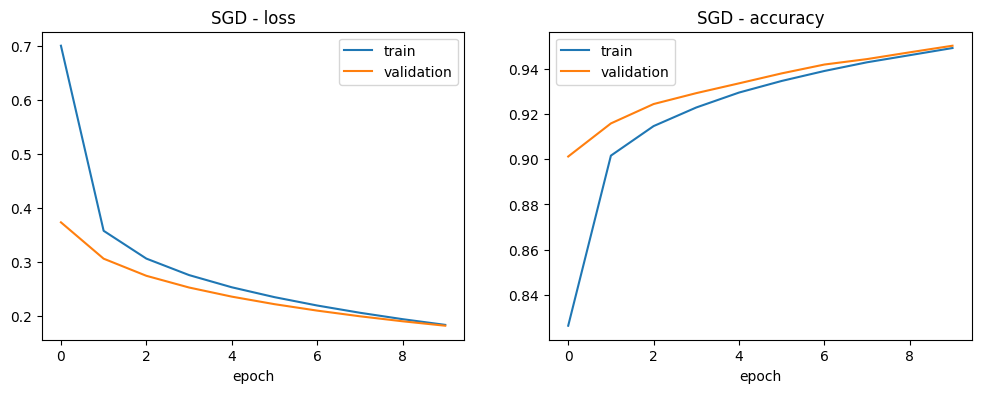

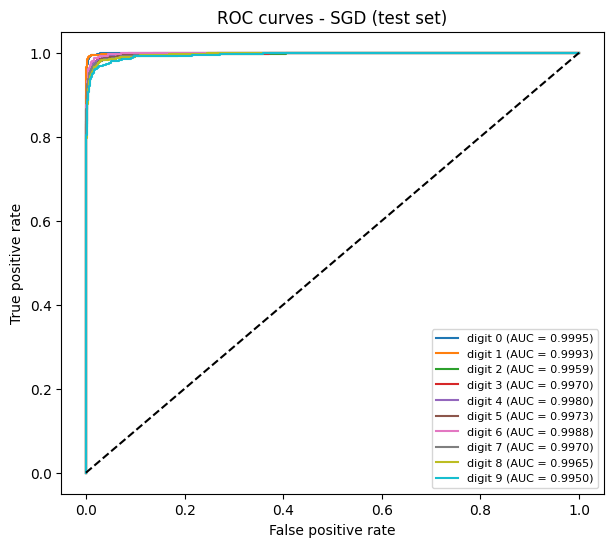

Test accuracy: 0.9481
              precision    recall  f1-score   support

           0     0.9536    0.9857    0.9694       980
           1     0.9781    0.9841    0.9811      1135
           2     0.9511    0.9428    0.9470      1032
           3     0.9325    0.9436    0.9380      1010
           4     0.9443    0.9501    0.9472       982
           5     0.9418    0.9249    0.9333       892
           6     0.9476    0.9624    0.9549       958
           7     0.9481    0.9416    0.9449      1028
           8     0.9451    0.9199    0.9324       974
           9     0.9336    0.9197    0.9266      1009

    accuracy                         0.9481     10000
   macro avg     0.9476    0.9475    0.9475     10000
weighted avg     0.9480    0.9481    0.9480     10000



In [7]:
plot_history(sgd_history, "SGD")
plot_roc(sgd_model, "ROC curves - SGD (test set)")
accuracy_table(sgd_model)

## Task 2: Adam and SGD with momentum

### Adam (learning_rate=0.001)

Epoch 1/10


1500/1500 - 2s - 2ms/step - accuracy: 0.9185 - loss: 0.2881 - val_accuracy: 0.9566 - val_loss: 0.1518


Epoch 2/10


1500/1500 - 2s - 1ms/step - accuracy: 0.9637 - loss: 0.1248 - val_accuracy: 0.9647 - val_loss: 0.1171


Epoch 3/10


...

1500/1500 - 2s - 1ms/step - accuracy: 0.9954 - loss: 0.0195 - val_accuracy: 0.9716 - val_loss: 0.1078


Epoch 9/10


1500/1500 - 2s - 1ms/step - accuracy: 0.9969 - loss: 0.0148 - val_accuracy: 0.9726 - val_loss: 0.1045


Epoch 10/10


1500/1500 - 2s - 1ms/step - accuracy: 0.9966 - loss: 0.0129 - val_accuracy: 0.9727 - val_loss: 0.1113


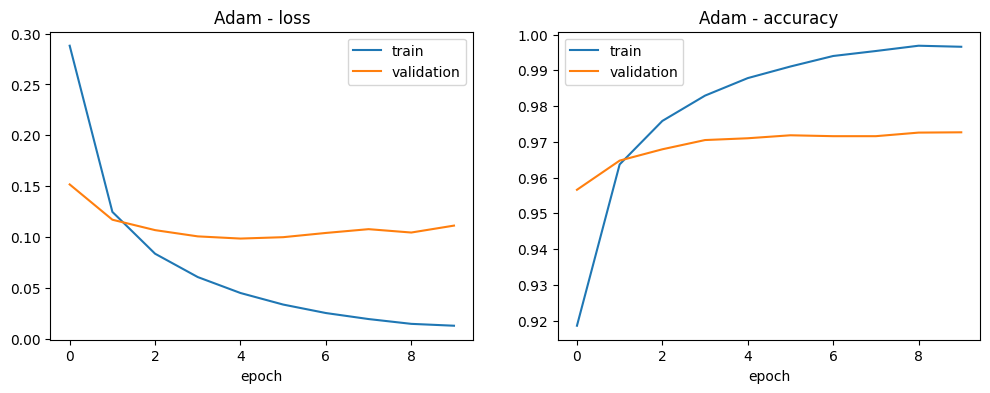

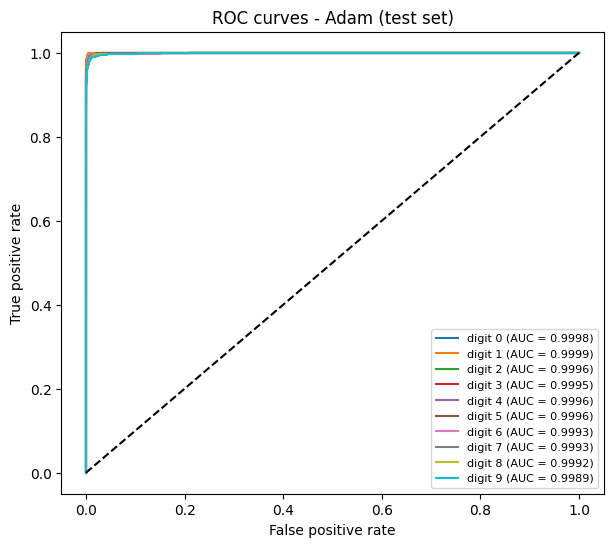

Test accuracy: 0.9737
              precision    recall  f1-score   support

           0     0.9700    0.9908    0.9803       980
           1     0.9886    0.9903    0.9894      1135
           2     0.9880    0.9603    0.9740      1032
           3     0.9674    0.9683    0.9678      1010
           4     0.9884    0.9582    0.9731       982
           5     0.9785    0.9675    0.9729       892
           6     0.9761    0.9812    0.9787       958
           7     0.9691    0.9776    0.9734      1028
           8     0.9613    0.9682    0.9647       974
           9     0.9497    0.9722    0.9608      1009

    accuracy                         0.9737     10000
   macro avg     0.9737    0.9735    0.9735     10000
weighted avg     0.9739    0.9737    0.9737     10000



In [8]:
adam_model = build_model(keras.optimizers.Adam(learning_rate=0.001))
adam_history = adam_model.fit(X_train, y_train, epochs=10, validation_split=0.2, verbose=2)

plot_history(adam_history, "Adam")
plot_roc(adam_model, "ROC curves - Adam (test set)")
accuracy_table(adam_model)

### SGD with momentum (momentum=0.9)

Epoch 1/10


1500/1500 - 2s - 1ms/step - accuracy: 0.9009 - loss: 0.3420 - val_accuracy: 0.9460 - val_loss: 0.1914


Epoch 2/10


1500/1500 - 1s - 882us/step - accuracy: 0.9528 - loss: 0.1649 - val_accuracy: 0.9596 - val_loss: 0.1418


Epoch 3/10


...

1500/1500 - 1s - 978us/step - accuracy: 0.9881 - loss: 0.0458 - val_accuracy: 0.9743 - val_loss: 0.0909


Epoch 9/10


1500/1500 - 1s - 844us/step - accuracy: 0.9904 - loss: 0.0394 - val_accuracy: 0.9743 - val_loss: 0.0892


Epoch 10/10


1500/1500 - 1s - 887us/step - accuracy: 0.9921 - loss: 0.0341 - val_accuracy: 0.9749 - val_loss: 0.0875


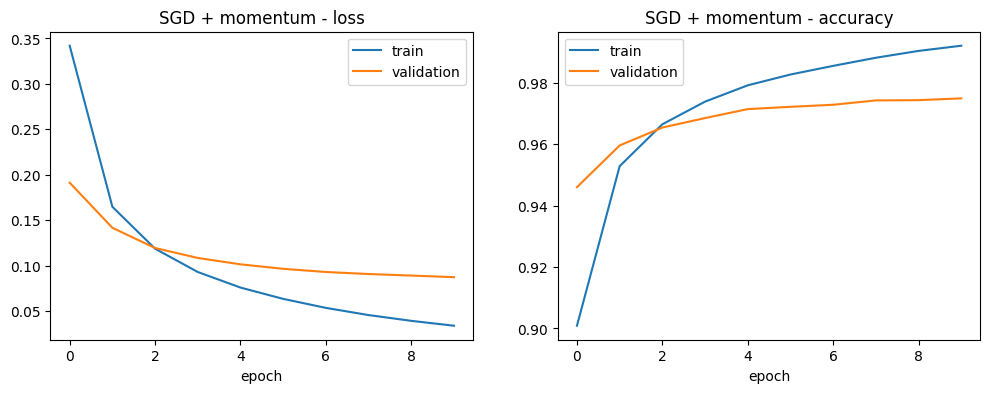

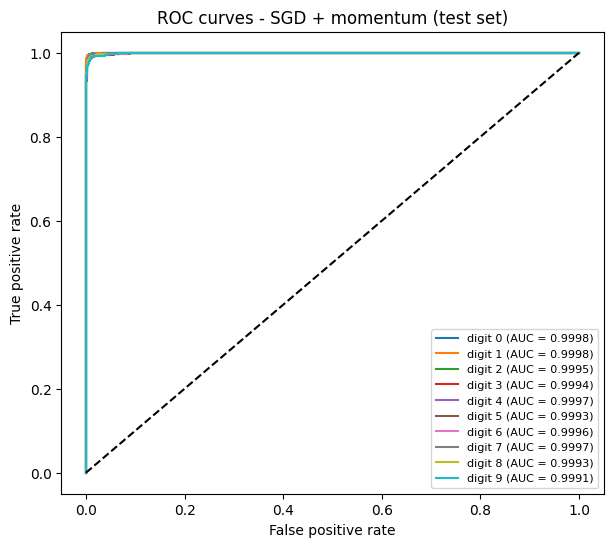

Test accuracy: 0.9774
              precision    recall  f1-score   support

           0     0.9700    0.9908    0.9803       980
           1     0.9903    0.9894    0.9899      1135
           2     0.9871    0.9612    0.9740      1032
           3     0.9734    0.9772    0.9753      1010
           4     0.9785    0.9756    0.9771       982
           5     0.9752    0.9709    0.9730       892
           6     0.9802    0.9823    0.9812       958
           7     0.9694    0.9854    0.9773      1028
           8     0.9694    0.9764    0.9729       974
           9     0.9789    0.9633    0.9710      1009

    accuracy                         0.9774     10000
   macro avg     0.9772    0.9773    0.9772     10000
weighted avg     0.9775    0.9774    0.9774     10000



In [9]:
momentum_model = build_model(keras.optimizers.SGD(learning_rate=0.01, momentum=0.9))
momentum_history = momentum_model.fit(X_train, y_train, epochs=10, validation_split=0.2, verbose=2)

plot_history(momentum_history, "SGD + momentum")
plot_roc(momentum_model, "ROC curves - SGD + momentum (test set)")
accuracy_table(momentum_model)

### Comparing the three optimisers

In [10]:
optimiser_models = {"SGD": sgd_model, "SGD + momentum": momentum_model, "Adam": adam_model}
optimiser_histories = {"SGD": sgd_history, "SGD + momentum": momentum_history, "Adam": adam_history}

summary(optimiser_models)

,Model,Train accuracy,Test accuracy,Train AUC,Test AUC
0,SGD,0.95135,0.9481,0.99779,0.99762
1,SGD + momentum,0.99233,0.9774,0.99993,0.99950
2,Adam,0.99400,0.9737,0.99998,0.99944


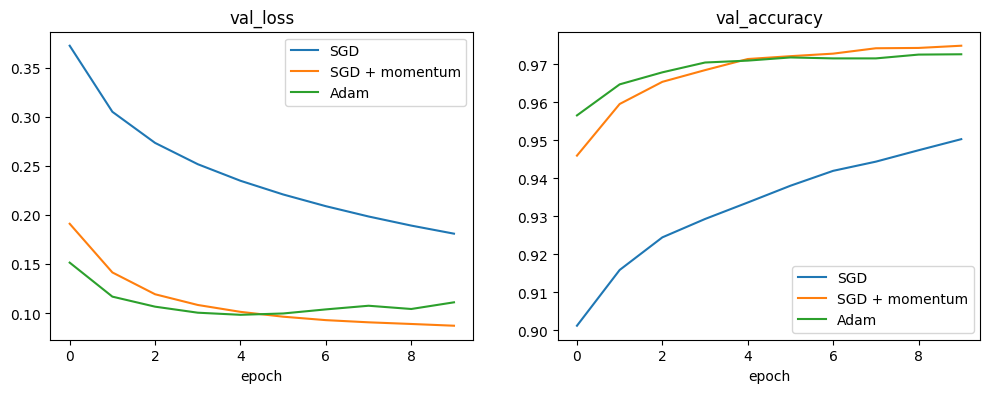

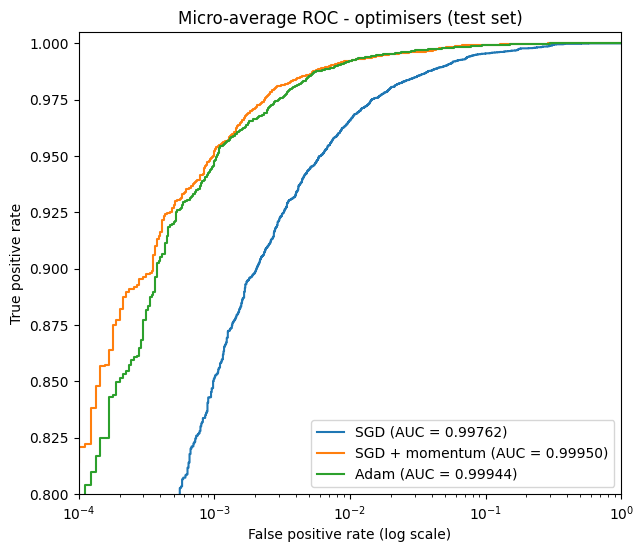

In [11]:
plt.figure(figsize=(12, 4))
for i, metric in enumerate(["val_loss", "val_accuracy"]):
    plt.subplot(1, 2, i + 1)
    for name, history in optimiser_histories.items():
        plt.plot(history.history[metric], label=name)
    plt.title(metric)
    plt.xlabel("epoch")
    plt.legend()
plt.show()

compare_roc(optimiser_models, "Micro-average ROC - optimisers (test set)")

**Do we see an improvement in backpropagation? Which optimiser performed best?**

Yes. Both momentum and Adam are a clear improvement on plain SGD.

| Model | Test accuracy | Test AUC (micro) |
|---|---|---|
| SGD | 0.9481 | 0.99762 |
| SGD + momentum | 0.9774 | 0.99950 |
| Adam | 0.9737 | 0.99944 |

- **Plain SGD** learns slowly. After 10 epochs its loss is still going down (val loss 0.18), so it has not finished learning. Its ROC curves are the lowest, and digits 5, 8 and 9 have the weakest AUCs.
- **Adam** learns the fastest. It reaches about 96.5% validation accuracy after only 2 epochs. However, its validation loss stops improving after epoch 5 (0.099) and then goes back up to 0.111, while its training accuracy reaches 99.7%. So Adam is already starting to overfit within 10 epochs.
- **SGD + momentum** improves more steadily. Its validation loss keeps going down for all 10 epochs (0.088 at the end).

On the zoomed (log-scale) ROC plot, the SGD curve sits clearly below the other two. The momentum and Adam curves are almost on top of each other. **SGD + momentum** has a slightly higher test AUC (0.99950 vs 0.99944) and higher test accuracy (97.7% vs 97.4%), so in this run it performed best. Adam is the fastest to train but has a bigger gap between train and test.

## Task 3: Regularisation

Plain Adam trained for 20 epochs is used as the reference, so we can see what happens without any regularisation.

Note: with L2 the Keras loss also includes the weight penalty, so its loss values are a bit higher than the other models.

Epoch 1/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9208 - loss: 0.2835 - val_accuracy: 0.9555 - val_loss: 0.1553


Epoch 2/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9632 - loss: 0.1258 - val_accuracy: 0.9648 - val_loss: 0.1193


Epoch 3/20


...

1500/1500 - 2s - 1ms/step - accuracy: 0.9978 - loss: 0.0071 - val_accuracy: 0.9728 - val_loss: 0.1440


Epoch 19/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9987 - loss: 0.0048 - val_accuracy: 0.9726 - val_loss: 0.1421


Epoch 20/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9985 - loss: 0.0050 - val_accuracy: 0.9718 - val_loss: 0.1494


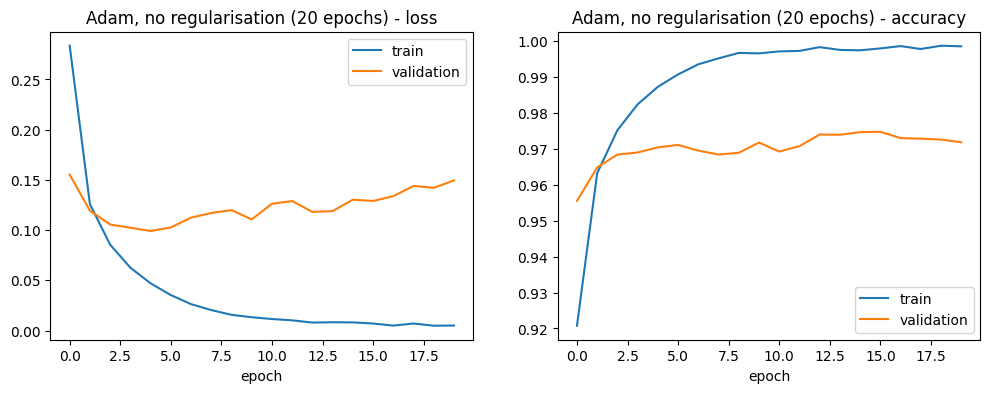

In [12]:
adam20_model = build_model(keras.optimizers.Adam(learning_rate=0.001))
adam20_history = adam20_model.fit(X_train, y_train, epochs=20, validation_split=0.2, verbose=2)

plot_history(adam20_history, "Adam, no regularisation (20 epochs)")

### L2 regularisation (lambda=0.001)

Epoch 1/20


1500/1500 - 2s - 2ms/step - accuracy: 0.9145 - loss: 0.4162 - val_accuracy: 0.9528 - val_loss: 0.2714


Epoch 2/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9535 - loss: 0.2502 - val_accuracy: 0.9630 - val_loss: 0.2220


Epoch 3/20


...

1500/1500 - 2s - 1ms/step - accuracy: 0.9803 - loss: 0.1357 - val_accuracy: 0.9719 - val_loss: 0.1635


Epoch 19/20


1500/1500 - 3s - 2ms/step - accuracy: 0.9812 - loss: 0.1341 - val_accuracy: 0.9687 - val_loss: 0.1757


Epoch 20/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9805 - loss: 0.1345 - val_accuracy: 0.9743 - val_loss: 0.1587


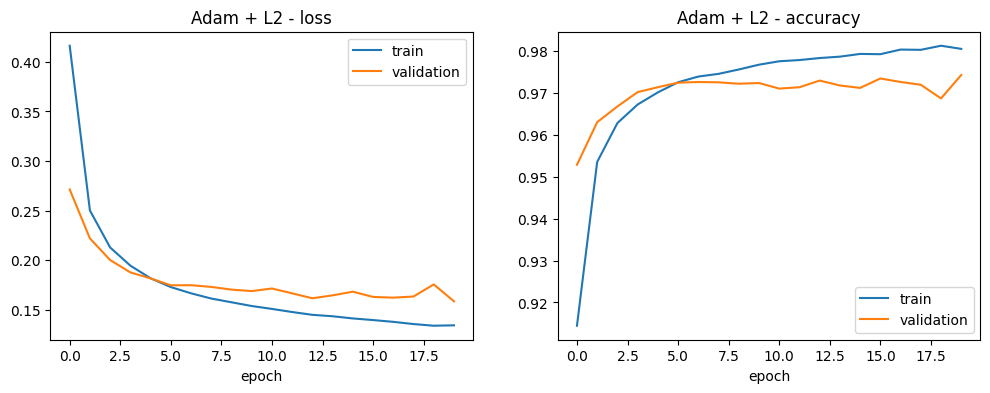

In [13]:
l2_model = build_model(keras.optimizers.Adam(learning_rate=0.001), l2=0.001)
l2_history = l2_model.fit(X_train, y_train, epochs=20, validation_split=0.2, verbose=2)

plot_history(l2_history, "Adam + L2")

### Dropout (rate=0.5)

Epoch 1/20


1500/1500 - 3s - 2ms/step - accuracy: 0.8740 - loss: 0.4260 - val_accuracy: 0.9498 - val_loss: 0.1784


Epoch 2/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9275 - loss: 0.2420 - val_accuracy: 0.9584 - val_loss: 0.1413


Epoch 3/20


...

1500/1500 - 2s - 2ms/step - accuracy: 0.9689 - loss: 0.0952 - val_accuracy: 0.9767 - val_loss: 0.0911


Epoch 19/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9695 - loss: 0.0936 - val_accuracy: 0.9765 - val_loss: 0.0962


Epoch 20/20


1500/1500 - 2s - 1ms/step - accuracy: 0.9703 - loss: 0.0926 - val_accuracy: 0.9753 - val_loss: 0.0926


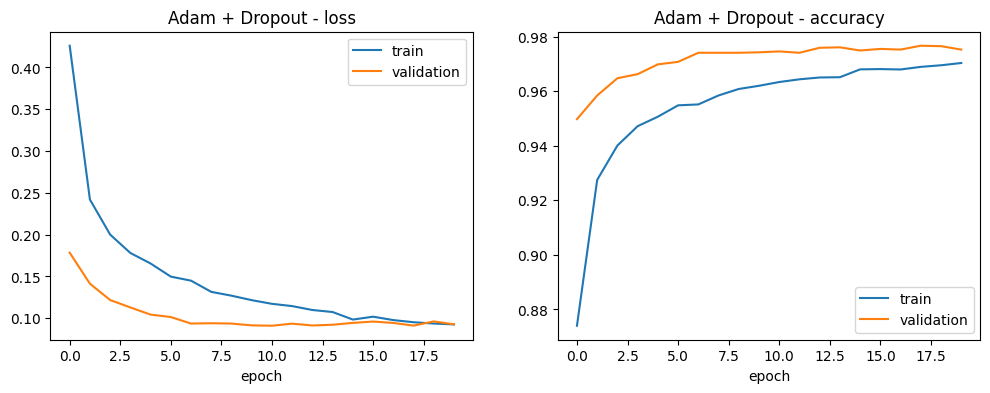

In [14]:
dropout_model = build_model(keras.optimizers.Adam(learning_rate=0.001), dropout=0.5)
dropout_history = dropout_model.fit(X_train, y_train, epochs=20, validation_split=0.2, verbose=2)

plot_history(dropout_history, "Adam + Dropout")

### Early stopping

Training stops when the validation loss has not improved for 5 epochs, and the best weights are kept.

Epoch 1/50


1500/1500 - 2s - 2ms/step - accuracy: 0.9196 - loss: 0.2850 - val_accuracy: 0.9577 - val_loss: 0.1540


Epoch 2/50


1500/1500 - 2s - 1ms/step - accuracy: 0.9624 - loss: 0.1289 - val_accuracy: 0.9668 - val_loss: 0.1173


Epoch 3/50


...

Epoch 11/50


1500/1500 - 2s - 1ms/step - accuracy: 0.9977 - loss: 0.0105 - val_accuracy: 0.9742 - val_loss: 0.1133


Epoch 12/50


1500/1500 - 2s - 1ms/step - accuracy: 0.9977 - loss: 0.0093 - val_accuracy: 0.9747 - val_loss: 0.1102


Stopped after 12 epochs


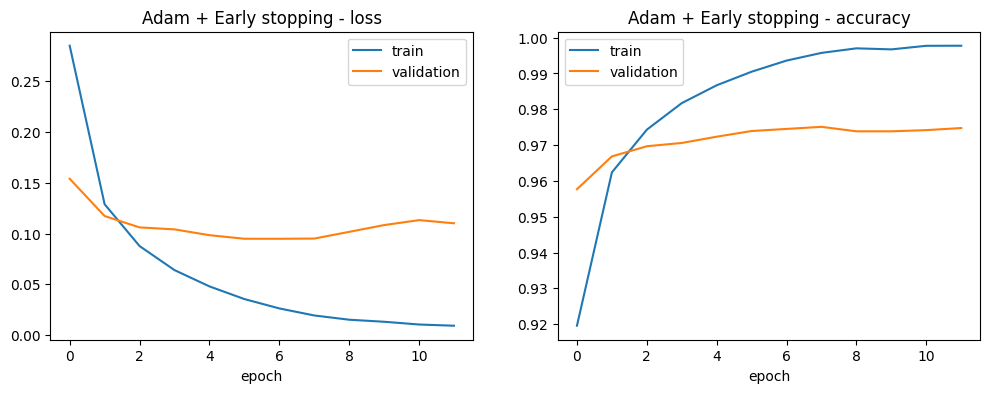

In [15]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

es_model = build_model(keras.optimizers.Adam(learning_rate=0.001))
es_history = es_model.fit(X_train, y_train, epochs=50, validation_split=0.2,
                          callbacks=[early_stop], verbose=2)

print("Stopped after", len(es_history.history["loss"]), "epochs")
plot_history(es_history, "Adam + Early stopping")

### All combined: L2 + Dropout + Early stopping (up to 50 epochs)

Epoch 1/50


1500/1500 - 3s - 2ms/step - accuracy: 0.8709 - loss: 0.5568 - val_accuracy: 0.9420 - val_loss: 0.3151


Epoch 2/50


1500/1500 - 3s - 2ms/step - accuracy: 0.9193 - loss: 0.3816 - val_accuracy: 0.9523 - val_loss: 0.2651


Epoch 3/50


...

Epoch 18/50


1500/1500 - 2s - 1ms/step - accuracy: 0.9423 - loss: 0.2850 - val_accuracy: 0.9688 - val_loss: 0.2046


Epoch 19/50


1500/1500 - 2s - 1ms/step - accuracy: 0.9439 - loss: 0.2820 - val_accuracy: 0.9693 - val_loss: 0.2050


Stopped after 19 epochs


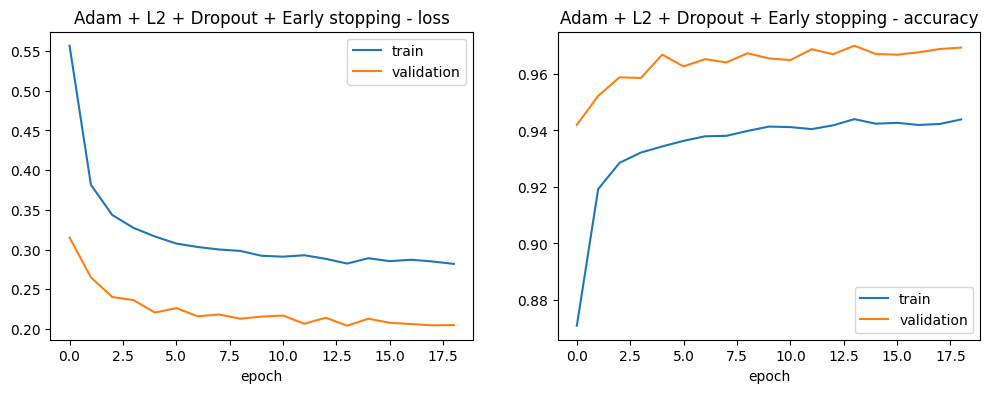

In [16]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

combined_model = build_model(keras.optimizers.Adam(learning_rate=0.001), l2=0.001, dropout=0.5)
combined_history = combined_model.fit(X_train, y_train, epochs=50, validation_split=0.2,
                                      callbacks=[early_stop], verbose=2)

print("Stopped after", len(combined_history.history["loss"]), "epochs")
plot_history(combined_history, "Adam + L2 + Dropout + Early stopping")

### Comparing the regularised models

In [17]:
reg_models = {
    "Adam (no regularisation)": adam20_model,
    "Adam + L2": l2_model,
    "Adam + Dropout": dropout_model,
    "Adam + Early stopping": es_model,
    "Adam + L2 + Dropout + ES": combined_model,
}

table = summary(reg_models)
table["Accuracy gap"] = table["Train accuracy"] - table["Test accuracy"]
table["AUC gap"] = table["Train AUC"] - table["Test AUC"]
table

,Model,Train accuracy,Test accuracy,Train AUC,Test AUC,Accuracy gap,AUC gap
0,Adam (no regularisation),0.99715,0.9739,0.99999,0.99936,0.02325,0.00063
1,Adam + L2,0.98394,0.9741,0.99980,0.99947,0.00984,0.00033
2,Adam + Dropout,0.99233,0.9757,0.99996,0.99953,0.01663,0.00043
3,Adam + Early stopping,0.99342,0.9766,0.99996,0.99949,0.01682,0.00047
4,Adam + L2 + Dropout + ES,0.97473,0.9703,0.99944,0.99920,0.00443,0.00024


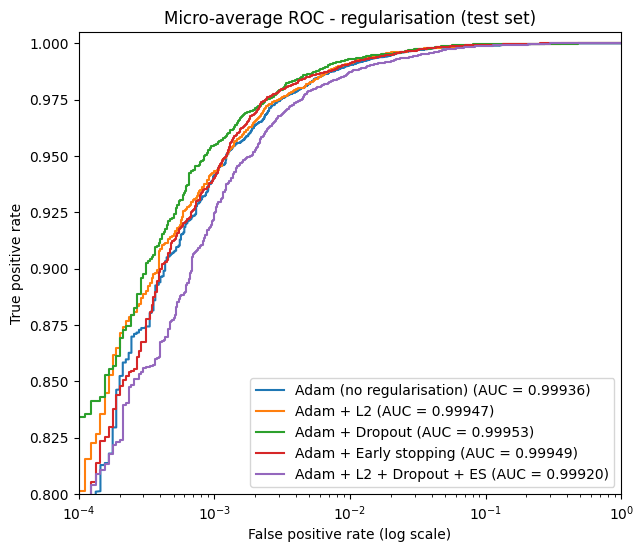

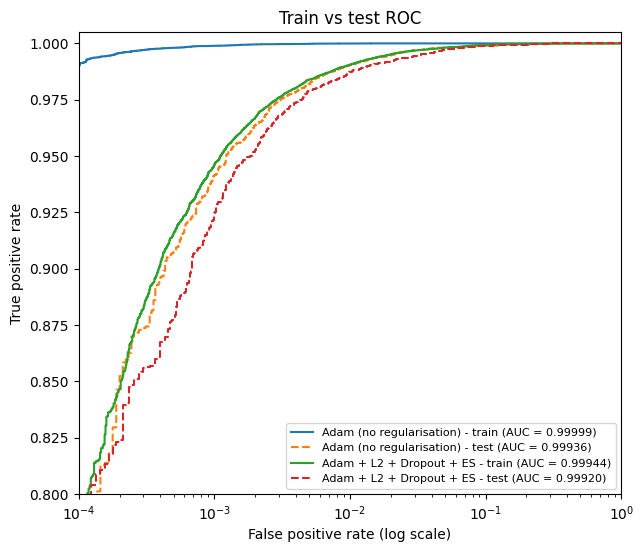

In [18]:
compare_roc(reg_models, "Micro-average ROC - regularisation (test set)")

# train vs test ROC: a big gap between the two curves is a sign of overfitting
plt.figure(figsize=(7, 6))
for name in ["Adam (no regularisation)", "Adam + L2 + Dropout + ES"]:
    model = reg_models[name]
    fpr, tpr, roc_auc = micro_roc(model, X_fit, y_fit)
    plt.plot(fpr, tpr, label=f"{name} - train (AUC = {roc_auc:.5f})")
    fpr, tpr, roc_auc = micro_roc(model, X_test, y_test)
    plt.plot(fpr, tpr, "--", label=f"{name} - test (AUC = {roc_auc:.5f})")
plt.xscale("log")
plt.xlim(1e-4, 1)
plt.ylim(0.8, 1.005)
plt.xlabel("False positive rate (log scale)")
plt.ylabel("True positive rate")
plt.title("Train vs test ROC")
plt.legend(loc="lower right", fontsize=8)
plt.show()

**Do we observe overfitting? Can we see it in the ROC curves?**

Yes. The model without regularisation clearly overfits.

- **Loss curves:** for plain Adam trained for 20 epochs, the training loss keeps falling to 0.005, but the validation loss is lowest at epoch 5 (0.099) and then rises to 0.149 by epoch 20. Training accuracy gets to 99.85% while validation accuracy stays around 97%. This is the classic sign of overfitting: the model keeps memorising the training data but does not get better on new data.
- **ROC curves:** on the train vs test ROC plot (log scale), the unregularised model's train curve sits almost in the top-left corner (AUC 0.99999), and its test curve sits visibly lower (AUC 0.99936). That gap between the train and test curves is the overfitting. For the combined model, the train and test curves are much closer together.

What each technique did (from the table above):

| Model | Train acc | Test acc | Accuracy gap | AUC gap |
|---|---|---|---|---|
| Adam (no regularisation) | 0.9972 | 0.9739 | 0.0233 | 0.00063 |
| Adam + L2 | 0.9839 | 0.9741 | 0.0098 | 0.00033 |
| Adam + Dropout | 0.9923 | 0.9757 | 0.0166 | 0.00043 |
| Adam + Early stopping | 0.9934 | 0.9766 | 0.0168 | 0.00047 |
| Adam + L2 + Dropout + ES | 0.9747 | 0.9703 | 0.0044 | 0.00024 |

- **L2** keeps the weights small. It cut the train/test gap by more than half, and its validation loss no longer rises.
- **Dropout** makes training harder (training accuracy is lower than validation accuracy for most epochs), and the validation loss stays flat at about 0.09 instead of rising.
- **Early stopping** ended training at epoch 12 and kept the weights from epoch 6, the epoch with the lowest validation loss. It gave the best test accuracy (97.66%).
- **All combined** has the smallest gap (0.4% accuracy, 0.00024 AUC), so it overfits the least. Its test accuracy is a little lower (97.0%) because using L2 and dropout together with early stopping (patience 5) is a lot of regularisation for such a small network. It is slightly underfitting rather than overfitting.

**Conclusion:** without regularisation the MLP overfits after about 5 epochs. Each technique reduces the gap between the train and test ROC curves. Early stopping (or dropout) gives the best balance between a small gap and high test accuracy.